# Normalised chr

If chr sizes are very different, but you only care about synteny you can normalise them to the same size. Here I was testing funciton that does that. 

Lets do it with two chr first.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display
from functions import plot

%matplotlib inline

Lets say chrA is 1Mb and chrB is 100 Mb. n1 and n2 are their sizes in bp.

Each has a gene one 25% of its size along or so. p1 and p2 are the gene positions.

In [2]:
n1 = 1_000_000
n2 = 100_000_000

p1 = 250_000
p2 = 25_000_000

## 2. Draw at real size

The bars start at 0 and their widths are n1 and n2. Red dots are our two genes. A is 100 times shorter than B, so it is barely visible.

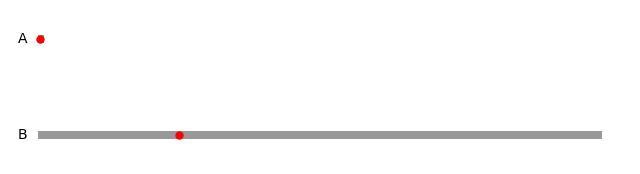

In [3]:
fig, ax = plt.subplots(figsize=(8, 2))

ax.add_patch(Rectangle((0, 0.96), n1, 0.08, facecolor="#999999"))
ax.add_patch(Rectangle((0, -0.04), n2, 0.08, facecolor="#999999"))
ax.plot(p1, 1, "o", color="red", markersize=5)
ax.plot(p2, 0, "o", color="red", markersize=5)

ax.text(-2_000_000, 1, "A", ha="right", va="center")
ax.text(-2_000_000, 0, "B", ha="right", va="center")
ax.set_xlim(-5_000_000, 105_000_000)
ax.set_ylim(-0.3, 1.3)
ax.axis("off")
plt.show()

Same as before, we divide the gene position by chr size.

For A: 250_000 / 1_000_000 = 0.25.

For B: 25_000_000 / 100_000_000 = 0.25.

Both genes sit at 25% of their chr length. Put in code gives us:

In [4]:
x1 = p1 / n1
x2 = p2 / n2
print(x1, x2)

0.25 0.25


Now both chr go from 0 to 1. We use x1 and x2 for the dots instead of the original bp positions. Both dots should sit 25% of bar.

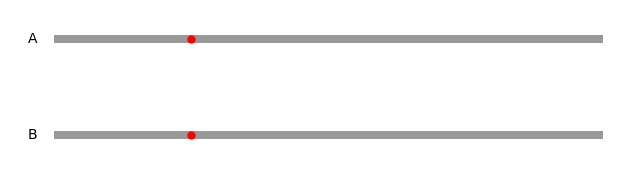

In [ ]:
fig, ax = plt.subplots(figsize=(8, 2))

ax.add_patch(Rectangle((0, 0.96), 1, 0.08, facecolor="#999999"))
ax.add_patch(Rectangle((0, -0.04), 1, 0.08, facecolor="#999999"))
ax.plot(x1, 1, "o", color="red", markersize=5)
ax.plot(x2, 0, "o", color="red", markersize=5)

ax.text(-0.03, 1, "A", ha="right", va="center")
ax.text(-0.03, 0, "B", ha="right", va="center")
ax.set_xlim(-0.08, 1.05)
ax.set_ylim(-0.3, 1.3)
ax.axis("off")
plt.show()

## 3. and if chr doenst starts with 0? 

If we have several chr next to each other. Lets say this bar starts at a = 1.1 and ends at b = 2.1.

Its width is b - a. So we multiply the relative position by that width and add the start:
x = a+(position/chr_size)*(b-a)

Our gene is still 25% along the bar, but now its plotted position is 1.35.

In [ ]:
a = 1.1
b = 2.1

x3 = a + (p1 / n1) * (b - a)
print(x3)

1.35


## 4. Use it in SynViser

Put `normalise_chrs = true` before the TOML tables. 

The input files still use bp. Chr ordering and size filters still use the real sizes but now the drawing "normalises" chr.

== normalised.toml ==
  spA-spB: 280 links
  spB-spC: 310 links
  auto-generated 4 focal colours
  saved examples/plot_normalised.png
  saved examples/plot_normalised.svg


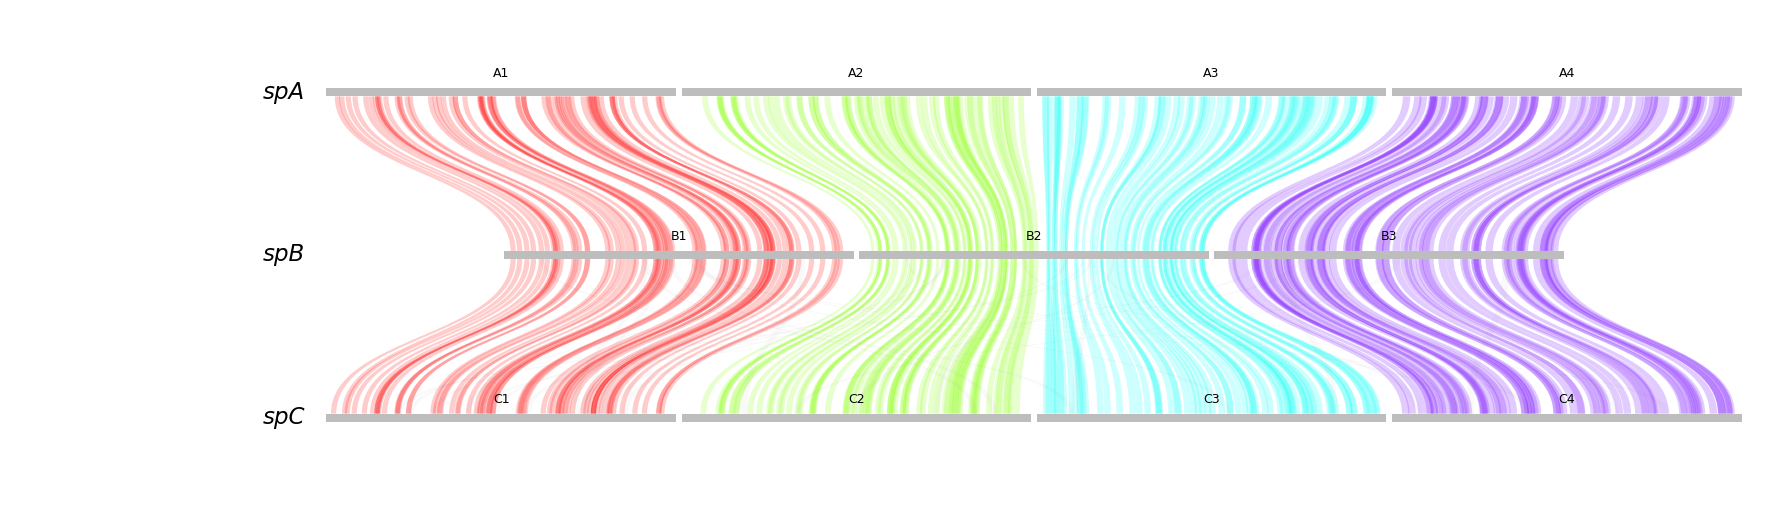

In [ ]:
plot("examples/normalised.toml")
display(Image("examples/plot_normalised.png"))

## 7. Final position function
This is how final funciton looks in the functions.py

In [8]:
def _x_of(track, chrom, pos, scale):
    if track.get("normalise_chrs", False):
        left, right = track["span"][chrom]
        return left + pos / track["chr_sizes"][chrom] * (right - left)
    return track["x_offset"] + (track["bp_before"][chrom] + pos) * scale